## Problem 9: Statement

Generate a time series of $10^5$ random numbers with an LCG with larger period (e.g., *drand48*) and compute $ \bar{X}$ and $\hat{\sigma}_x^2 $ for $N=10^3, 10^4, 10^5$ random numbers- Compare the values with the exact analytical results. Repeat problems 7d) and 7e) with this LCG.


## Problem 9: Solution

We use the LCG of *drand48*,

$$
X_{i+1}=(aX_i+c) \bmod m \tag{1}
$$

with $a=25214903917$, $c=11$ and $m=2^{48}$, which has the period $2^{48}\approx2.8\cdot10^{14}$. As in Problem 7 we start with $X_0=1$ and normalise with $U_i=X_i/m\in[0,1)$.

In [1]:
import numpy as np
from matplotlib import pyplot as plt

a = 25214903917
c = 11
m = 2**48
X_0 = 1

def LCG(n):
    X = [X_0]
    for i in range(n):
        X.append((a*X[-1]+c) % m)
    return X

X = LCG(10**5)
U = np.array(X)/m

print("First 10 U_i:", U[:10])


First 10 U_i: [3.55271368e-15 8.95813341e-05 7.31953177e-01 8.72086605e-01
 3.75548061e-01 7.94304827e-01 3.64145797e-01 3.10017609e-01
 9.45356593e-01 1.56539656e-01]


Now we compute the average and the estimator for the variance

$$
\bar{X}=\frac{1}{N}\sum_{i=1}^{N}U_i, \qquad \hat{\sigma}_X^2=\overline{X^2}-\bar{X}^2 \tag{2}
$$

for $N=10^3,10^4,10^5$ and compare them with the exact values $1/2$ and $1/12$ of equally distributed numbers in $[0,1)$.

In [2]:
print("EXACT VALUES: mean =", 1/2, ", variance =", 1/12)

for N in [10**3, 10**4, 10**5]:
    X_bar = np.mean(U[1:N+1])
    X2_bar = np.mean(U[1:N+1]**2)
    print(f"For N={N}: mean = {X_bar:.6f}, variance = {X2_bar - X_bar**2:.6f}, "
          f"difference mean = {X_bar - 1/2:.6f}, difference variance = {X2_bar - X_bar**2 - 1/12:.6f}")


EXACT VALUES: mean = 0.5 , variance = 0.08333333333333333
For N=1000: mean = 0.497215, variance = 0.083804, difference mean = -0.002785, difference variance = 0.000471
For N=10000: mean = 0.499305, variance = 0.083307, difference mean = -0.000695, difference variance = -0.000026
For N=100000: mean = 0.499118, variance = 0.083124, difference mean = -0.000882, difference variance = -0.000209


Unlike in Problem 7, the values now approach the exact results as $N$ increases. For independent random numbers the statistical error of the average is $\sigma/\sqrt{N}=1/\sqrt{12N}$, which is about $0.009$, $0.003$ and $0.0009$ for the three values of $N$. The differences to the exact values are not larger than this.

Repeating Problem 7(d), we plot the running average

$$
\bar{X}(n)=\frac{1}{n}\sum_{i=1}^{n}U_i \tag{3}
$$

for $n\in[30000,40000]$.

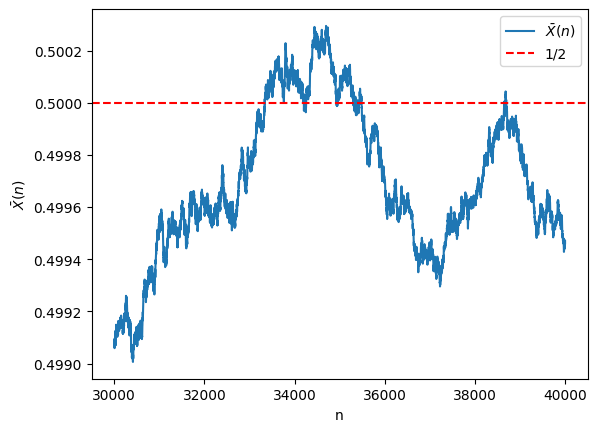

In [3]:
running_average = np.cumsum(U[1:])/np.arange(1, len(U))

n = np.arange(30000, 40001)

plt.plot(n, running_average[n-1], label=r"$\bar{X}(n)$")
plt.axhline(1/2, linestyle="--", color="red", label="1/2")
plt.xlabel("n")
plt.ylabel(r"$\bar{X}(n)$")
plt.legend()
plt.show()


Figure 1. Running average $\bar{X}(n)$ for $n\in[30000,40000]$ of the drand48 LCG

Repeating Problem 7(e), we plot $x=U_i$ against $y=U_{i+1}$ for $i=1,3,5,\dots$

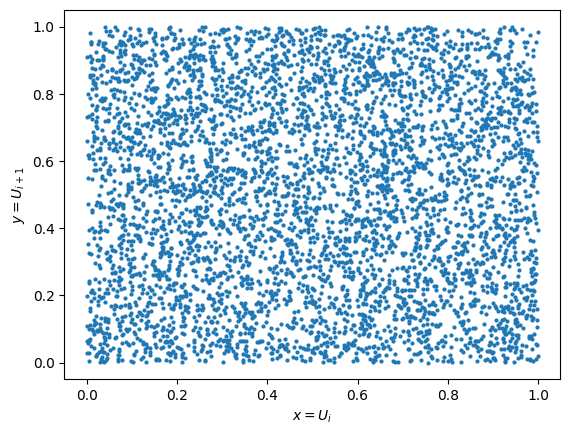

In [4]:
x = U[1:10**4:2]
y = U[2:10**4+1:2]

plt.plot(x, y, ".", markersize=4)
plt.xlabel(r"$x=U_i$")
plt.ylabel(r"$y=U_{i+1}$")
plt.show()


Figure 2. $U_{i+1}$ against $U_i$ for $i=1,3,5,\dots,9999$ of the drand48 LCG

## Problem 10: Statement

Modify your MOnte Carlo computer program of Problem 8 for the simulation of the 1D Ising model with

(a) periodic boundary conditions and
(b) the Glauber update algorithm

Determine as in Problem 8 the mean energy, specific heat, magnetisation and susceptibility for $N=10,100,1000,10000$ spins and different temperatures in the inverse temperature range $\beta = J/(k_bT)=0,...,2$. Check your simulations by comparison with the exact comparisons for the mean energy and specific heat. Compare also with the numerical results of Problem 8.

## Problem 10: Solution


We modify the program of Problem 8 in two ways.

(a) With periodic boundary conditions the spins $s_1$ and $s_N$ are neighbours as well, so the energy is

$$
E=-J\sum_{i=1}^{N}s_is_{i+1}, \qquad s_{N+1}=s_1 \tag{4}
$$

and in the energy change of a spin flip

$$
\Delta E=2Js_i(s_{i-1}+s_{i+1}) \tag{5}
$$

every spin has two neighbours, with $s_0=s_N$ and $s_{N+1}=s_1$.

(b) In the Glauber algorithm a proposed flip is accepted with probability

$$
p=\frac{e^{-\beta\Delta E}}{1+e^{-\beta\Delta E}}=\frac{1}{1+e^{\beta\Delta E}} \tag{6}
$$

instead of the Metropolis probability $\min(1,e^{-\beta\Delta E})$.

We measure the same quantities as in Problem 8, eqs. (9) and (10):

$$
e=\frac{\langle E\rangle}{N}, \qquad c=\frac{\beta^2}{N}\left(\langle E^2\rangle-\langle E\rangle^2\right), \qquad m=\frac{\langle |M|\rangle}{N}, \qquad \chi=\frac{\beta}{N}\langle M^2\rangle \tag{7}
$$

We add the two modifications as options `periodic` and `glauber` to the program of Problem 8, so that with both set to `False` it is the program of Problem 8.

In [5]:
import numpy as np
import time
from numba import njit, prange
from matplotlib import pyplot as plt

J = 1.0
k_b = 1.0

@njit
def ising_mc(N, beta, n_therm, n_sweeps, seed, periodic, glauber):
    np.random.seed(seed)

    # random start configuration
    s = np.ones(N)
    for i in range(N):
        if np.random.random() < 0.5:
            s[i] = -1

    E = 0.0
    for i in range(N-1):
        E += -J*s[i]*s[i+1]
    if periodic:
        E += -J*s[N-1]*s[0]
    M = np.sum(s)

    E_sum = 0.0
    E2_sum = 0.0
    M_sum = 0.0
    M2_sum = 0.0

    for sweep in range(n_therm + n_sweeps):
        for step in range(N):
            i = np.random.randint(N)
            if periodic:
                neighbours = s[(i-1) % N] + s[(i+1) % N]
            else:
                neighbours = 0.0
                if i > 0:
                    neighbours += s[i-1]
                if i < N-1:
                    neighbours += s[i+1]
            dE = 2*J*s[i]*neighbours
            if glauber:
                accept = np.random.random() < 1/(1 + np.exp(beta*dE))
            else:
                accept = dE <= 0 or np.random.random() < np.exp(-beta*dE)
            if accept:
                s[i] = -s[i]
                E += dE
                M += 2*s[i]
        if sweep >= n_therm:
            E_sum += E
            E2_sum += E*E
            M_sum += abs(M)
            M2_sum += M*M

    return E_sum/n_sweeps, E2_sum/n_sweeps, M_sum/n_sweeps, M2_sum/n_sweeps

@njit(parallel=True)
def simulate(N, betas, n_therm, n_sweeps, periodic, glauber):
    results = np.zeros((len(betas), 4))
    for k in prange(len(betas)):
        E, E2, M_abs, M2 = ising_mc(N, betas[k], n_therm, n_sweeps, 1000*N + k, periodic, glauber)
        results[k, 0] = E
        results[k, 1] = E2
        results[k, 2] = M_abs
        results[k, 3] = M2
    return results


Now we run three simulations for every $N$ and $\beta=0,0.1,\dots,2$: periodic boundary conditions with the Metropolis algorithm (a), periodic boundary conditions with the Glauber algorithm (b), and free boundary conditions with the Metropolis algorithm, i.e. the program of Problem 8.

In [6]:
betas = np.linspace(0, 2, 21)
N_values = [10, 100, 1000, 10000]

n_therm = 10**4
n_sweeps = {10: 400000, 100: 400000, 1000: 200000, 10000: 50000}

def run(periodic, glauber):
    e, c, m, chi = {}, {}, {}, {}
    for N in N_values:
        results = simulate(N, betas, n_therm, n_sweeps[N], periodic, glauber)
        E, E2, M_abs, M2 = results[:, 0], results[:, 1], results[:, 2], results[:, 3]
        e[N] = E/N
        c[N] = betas**2*(E2 - E**2)/N
        m[N] = M_abs/N
        chi[N] = betas*M2/N
    return e, c, m, chi

print("MONTE CARLO SIMULATION:")
t_start = time.time()
e_per, c_per, m_per, chi_per = run(periodic=True, glauber=False)
print(f"Periodic, Metropolis: done in {time.time() - t_start:.1f} s")
t_start = time.time()
e_gla, c_gla, m_gla, chi_gla = run(periodic=True, glauber=True)
print(f"Periodic, Glauber: done in {time.time() - t_start:.1f} s")
t_start = time.time()
e_free, c_free, m_free, chi_free = run(periodic=False, glauber=False)
print(f"Free, Metropolis (Problem 8): done in {time.time() - t_start:.1f} s")


MONTE CARLO SIMULATION:


Periodic, Metropolis: done in 36.4 s


Periodic, Glauber: done in 42.7 s


Free, Metropolis (Problem 8): done in 34.2 s


For periodic boundary conditions the partition function is, as derived in the lecture with the transfer matrix (see Homework 2, Problem 4),

$$
Z=\lambda_+^N+\lambda_-^N, \qquad \lambda_+=2\cosh(\beta J), \quad \lambda_-=2\sinh(\beta J) \tag{8}
$$

Since $d\lambda_\pm/d\beta=J\lambda_\mp$, we get with $\langle E\rangle=-\frac{1}{Z}\frac{\partial Z}{\partial\beta}$ and $\langle E^2\rangle=\frac{1}{Z}\frac{\partial^2 Z}{\partial\beta^2}$, after dividing numerator and denominator by $\lambda_+^N$ and writing $t=\tanh(\beta J)$,

$$
e=\frac{\langle E\rangle}{N}=-J\frac{t+t^{N-1}}{1+t^N} \tag{9}
$$

$$
\langle E^2\rangle=J^2N\frac{(N-1)\left(t^2+t^{N-2}\right)+1+t^N}{1+t^N}, \qquad c=\frac{\beta^2}{N}\left(\langle E^2\rangle-\langle E\rangle^2\right) \tag{10}
$$

In [7]:
def e_periodic(N, beta):
    t = np.tanh(J*beta)
    return -J*(t + t**(N-1))/(1 + t**N)

def c_periodic(N, beta):
    t = np.tanh(J*beta)
    E = N*e_periodic(N, beta)
    E2 = J**2*N*((N-1)*(t**2 + t**(N-2)) + 1 + t**N)/(1 + t**N)
    return beta**2*(E2 - E**2)/N


Check against the exact results. Points are Monte Carlo (circles: Metropolis, crosses: Glauber), lines are eqs. (9) and (10).

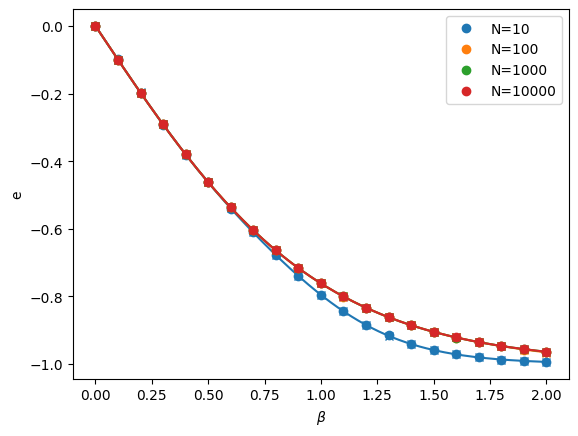

In [8]:
beta_fine = np.linspace(0, 2, 200)
colors = ["C0", "C1", "C2", "C3"]

for N, col in zip(N_values, colors):
    plt.plot(betas, e_per[N], "o", color=col, label=f"N={N}")
    plt.plot(betas, e_gla[N], "x", color=col)
    plt.plot(beta_fine, e_periodic(N, beta_fine), color=col)
plt.xlabel(r"$\beta$")
plt.ylabel("e")
plt.legend()
plt.show()


Figure 3. Mean energy per spin $e$ for periodic boundary conditions as a function of $\beta$. Circles: Metropolis, crosses: Glauber, lines: exact result eq. (9)

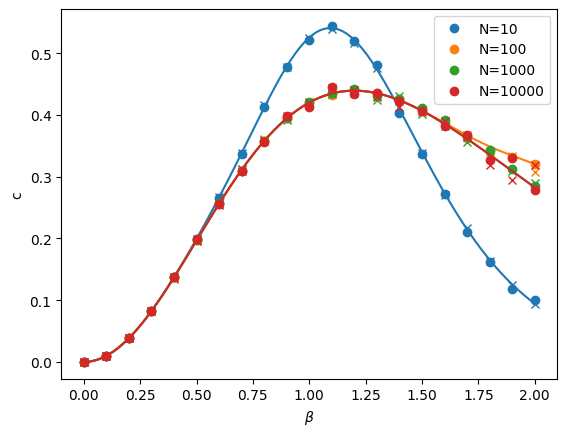

In [9]:
for N, col in zip(N_values, colors):
    plt.plot(betas, c_per[N], "o", color=col, label=f"N={N}")
    plt.plot(betas, c_gla[N], "x", color=col)
    plt.plot(beta_fine, c_periodic(N, beta_fine), color=col)
plt.xlabel(r"$\beta$")
plt.ylabel("c")
plt.legend()
plt.show()


Figure 4. Specific heat per spin $c$ for periodic boundary conditions as a function of $\beta$. Circles: Metropolis, crosses: Glauber, lines: exact result eq. (10)

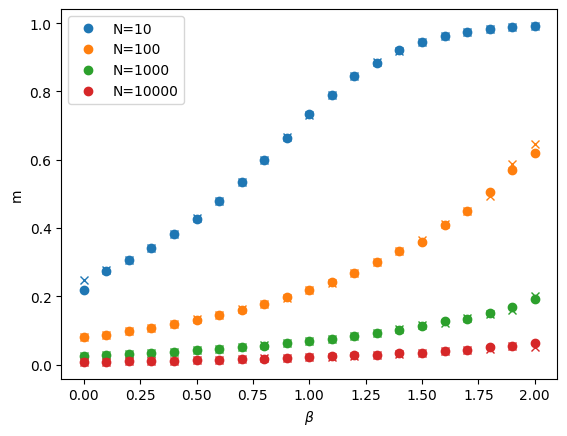

In [10]:
for N, col in zip(N_values, colors):
    plt.plot(betas, m_per[N], "o", color=col, label=f"N={N}")
    plt.plot(betas, m_gla[N], "x", color=col)
plt.xlabel(r"$\beta$")
plt.ylabel("m")
plt.legend()
plt.show()


Figure 5. Magnetisation per spin $m$ for periodic boundary conditions as a function of $\beta$. Circles: Metropolis, crosses: Glauber

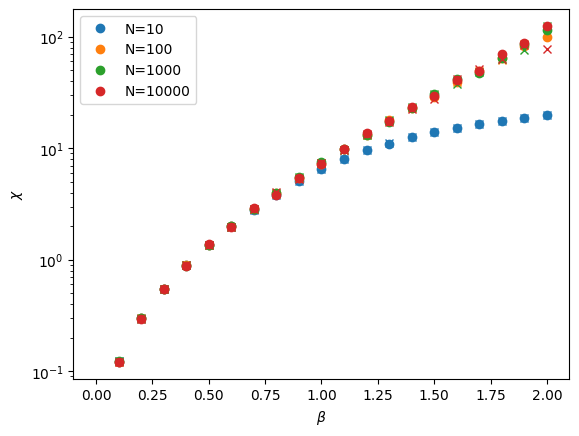

In [11]:
for N, col in zip(N_values, colors):
    plt.plot(betas, chi_per[N], "o", color=col, label=f"N={N}")
    plt.plot(betas, chi_gla[N], "x", color=col)
plt.yscale("log")
plt.xlabel(r"$\beta$")
plt.ylabel(r"$\chi$")
plt.legend()
plt.show()


Figure 6. Susceptibility per spin $\chi$ for periodic boundary conditions as a function of $\beta$ (logarithmic y-scale). Circles: Metropolis, crosses: Glauber

Comparison with Problem 8 (free boundary conditions, Metropolis) at $\beta=1$:

In [12]:
k = 10
print(f"beta={betas[k]:.1f} (free, Metropolis / periodic, Metropolis / periodic, Glauber):")
for N in N_values:
    print(f"N={N}:")
    print(f"   e   = {e_free[N][k]:.4f} / {e_per[N][k]:.4f} / {e_gla[N][k]:.4f}")
    print(f"   c   = {c_free[N][k]:.4f} / {c_per[N][k]:.4f} / {c_gla[N][k]:.4f}")
    print(f"   m   = {m_free[N][k]:.4f} / {m_per[N][k]:.4f} / {m_gla[N][k]:.4f}")
    print(f"   chi = {chi_free[N][k]:.4f} / {chi_per[N][k]:.4f} / {chi_gla[N][k]:.4f}")


beta=1.0 (free, Metropolis / periodic, Metropolis / periodic, Glauber):
N=10:
   e   = -0.6863 / -0.7974 / -0.7954
   c   = 0.3769 / 0.5216 / 0.5250
   m   = 0.6097 / 0.7333 / 0.7298
   chi = 4.8994 / 6.5037 / 6.4634
N=100:
   e   = -0.7539 / -0.7616 / -0.7614
   c   = 0.4161 / 0.4195 / 0.4179
   m   = 0.2162 / 0.2172 / 0.2185
   chi = 7.1856 / 7.2795 / 7.3661
N=1000:
   e   = -0.7607 / -0.7616 / -0.7618
   c   = 0.4172 / 0.4207 / 0.4215
   m   = 0.0690 / 0.0692 / 0.0687
   chi = 7.4531 / 7.5240 / 7.3856
N=10000:
   e   = -0.7615 / -0.7616 / -0.7616
   c   = 0.4214 / 0.4124 / 0.4195
   m   = 0.0218 / 0.0214 / 0.0219
   chi = 7.4334 / 7.1583 / 7.4327


As we can see on Fig. 3 and Fig. 4, the Monte Carlo results for $e$ and $c$ agree with the exact results eqs. (9) and (10) for all $N$ and both algorithms. Metropolis and Glauber give the same results, since both sample the same Boltzmann distribution. The only difference is $m$ at $\beta=0$ (Fig. 5), where the Metropolis value is too small for the same reason as in Problem 8. The Glauber algorithm accepts a flip at $\beta=0$ only with probability $1/2$ and does not have this problem.

Compared with Problem 8, for $N=10$ periodic boundary conditions give a lower energy and larger $c$, $m$ and $\chi$, since the chain has $N$ instead of $N-1$ bonds and no free ends. This boundary effect decreases like $1/N$: the energies differ by about $1\%$ for $N=100$ and agree for $N=10000$.